# Week 6 - Task D2 (bonus): the same pipeline on real data

**Question.** Is Pakistan's shift to solar electricity real, or is it arithmetic? The same question the board asked about the synthetic grid, now on a real file.

**Data.** Our World in Data, energy dataset, `owid-energy-data.csv` (built on Ember's yearly electricity data and the Energy Institute Statistical Review), https://github.com/owid/energy-data. **Downloaded 31 October 2026.** `get_data.py` re-downloads it and saves the extract in `data/` (all entities, every electricity column, 1985 onwards, untouched). The SHA-256 of the file I used is in `data/SOURCE.txt`.

Same pipeline as Task A to C: audit, clean, decisions table, one figure.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    HERE = Path(__file__).resolve().parent
    IN_NOTEBOOK = False
except NameError:
    HERE = Path.cwd()
    IN_NOTEBOOK = True
for cand in (HERE.parent, HERE, HERE.parent / "assignments"):
    if (cand / "vizlib.py").exists():
        sys.path.insert(0, str(cand))
        break


def show():
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import vizlib as vz
from vizlib import PALETTE, save_fig, style_defaults

style_defaults()
ORANGE, GREY, INK, SOFT = PALETTE["highlight"], PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
RAW = HERE / "data" / "owid_energy_extract.csv"
if not RAW.exists():
    raise SystemExit("data/owid_energy_extract.csv missing: run get_data.py first")
DOWNLOADED = "31 Oct 2026"
DECISIONS = []

## 1 · Audit

In [2]:
raw = pd.read_csv(RAW)
df = raw.copy()
print(f"rows {len(df):,}, columns {df.shape[1]}, years {df.year.min()}-{df.year.max()}")
print("dtypes:", ", ".join(f"{c}={t}" for c, t in df.dtypes.astype(str).items()))
print(f"key (country, year) duplicated: {int(df.duplicated(['country', 'year']).sum())}")
gen = df.electricity_generation
print(f"electricity_generation (the divisor for any share): {gen.notna().sum():,} values, min {gen.min()}, negatives {(gen < 0).sum()}, zeros {(gen == 0).sum()}")

# defect 1: the `country` column is not only countries
noiso = sorted(df.loc[df.iso_code.isna(), "country"].unique())
FORMER = ["Czechoslovakia", "East Germany", "West Germany", "USSR", "Yugoslavia", "Serbia and Montenegro", "Kosovo"]
aggs = [c for c in noiso if c not in FORMER]
print(f"\nentities with no ISO code: {len(noiso)} -> {len(aggs)} aggregates (e.g. {', '.join(aggs[:4])}, World, 'High-income countries') "
      f"and {len([c for c in FORMER if c in noiso])} real but former / partly recognised countries ({', '.join(c for c in FORMER if c in noiso)})")
y = 2023
world = df[(df.country == "World") & (df.year == y)].electricity_generation.iloc[0]
all_rows = df[df.year == y].electricity_generation.sum()
countries = df[(df.year == y) & df.iso_code.notna()].electricity_generation.sum()
print(f"{y}: World = {world:,.0f} TWh | every row summed = {all_rows:,.0f} TWh ({all_rows / world:.1f}x World) | ISO-coded rows only = {countries:,.0f} TWh ({countries / world:.3f}x)")
DECISIONS.append(("`country` mixes countries with {} aggregate rows (continents, income groups, and the same region from several sources: 'Africa (EI)', 'Africa (Ember)'...)".format(len(aggs)),
                  f"Entities with no ISO code; every row summed for {y} = {all_rows / world:.1f}x the World row",
                  "A country is a row with an ISO-3 code. The 7 former / partly recognised countries are named, not counted as aggregates. Nothing is ever summed across all rows",
                  f"{int(df.country.isin(aggs).sum()):,} aggregate rows excluded from any country total"))

rows 11,964, columns 19, years 1985-2025
dtypes: country=str, year=int64, iso_code=str, population=float64, electricity_generation=float64, coal_electricity=float64, gas_electricity=float64, oil_electricity=float64, fossil_electricity=float64, hydro_electricity=float64, nuclear_electricity=float64, solar_electricity=float64, wind_electricity=float64, biofuel_electricity=float64, other_renewable_electricity=float64, other_renewable_exc_biofuel_electricity=float64, renewables_electricity=float64, low_carbon_electricity=float64, solar_share_elec=float64
key (country, year) duplicated: 0
electricity_generation (the divisor for any share): 7,913 values, min 0.0, negatives 0, zeros 26

entities with no ISO code: 94 -> 87 aggregates (e.g. ASEAN (Ember), Africa, Africa (EI), Africa (EIA), World, 'High-income countries') and 7 real but former / partly recognised countries (Czechoslovakia, East Germany, West Germany, USSR, Yugoslavia, Serbia and Montenegro, Kosovo)
2023: World = 29,665 TWh | eve

In [3]:
pk = df[df.country == "Pakistan"].set_index("year").sort_index()
assert pk.index.is_unique and (np.diff(pk.index) == 1).all()
PARTS = ["coal_electricity", "gas_electricity", "oil_electricity", "nuclear_electricity", "hydro_electricity",
         "solar_electricity", "wind_electricity", "other_renewable_electricity"]
EXTRA = ["biofuel_electricity", "fossil_electricity", "renewables_electricity", "low_carbon_electricity", "other_renewable_exc_biofuel_electricity"]

# defect 2: columns that look like parts but are subsets or totals of other columns
naive_cols = [c for c in pk.columns if c.endswith("_electricity")]
naive = pk.loc[2000:, naive_cols].sum(axis=1)
parts_sum = pk.loc[2000:, PARTS].sum(axis=1)
with_bio = pk.loc[2000:, PARTS + ["biofuel_electricity"]].sum(axis=1)
print(f"\nPakistan, {len(naive_cols)} columns end in _electricity. Summed blindly they give {(naive / pk.loc[2000:, 'electricity_generation']).min():.2f}-"
      f"{(naive / pk.loc[2000:, 'electricity_generation']).max():.2f}x the total.")
print(f"the 8 exclusive parts sum to the total within {float((parts_sum - pk.loc[2000:, 'electricity_generation']).abs().max()):.3f} TWh in every year 2000-{pk.index.max()}")
over = (with_bio - pk.loc[2000:, "electricity_generation"])
print(f"adding biofuel_electricity as a 9th part over-counts by up to {over.max():.2f} TWh ({over.idxmax()}): "
      f"'other_renewable_electricity' already includes bioenergy (other_renewable_exc_biofuel is {pk.other_renewable_exc_biofuel_electricity.loc[2000:].max():.2f} every year)")
DECISIONS.append(("Columns that look like parts are not exclusive: `biofuel` sits inside `other_renewable`, and `fossil`, `renewables`, `low_carbon` are totals of other columns",
                  "Exclusivity test on Pakistan: 8 parts match the total exactly; adding `biofuel` overshoots by up to {:.2f} TWh; all {} columns summed = {:.1f}x".format(over.max(), len(naive_cols), (naive / pk.loc[2000:, 'electricity_generation']).max()),
                  "Use exactly 8 exclusive parts: coal, gas, oil, nuclear, hydro, solar, wind, other renewables (incl. bioenergy). Shares are over their sum, checked against the published total",
                  f"{len(EXTRA)} columns not used as parts"))

# defect 3: the fuel split is missing before 2000, while the total is not
pre = pk.loc[1985:1999]
print(f"\n1985-1999: electricity_generation present in {pre.electricity_generation.notna().sum()} of {len(pre)} years, "
      f"coal/gas/oil present in {pre.coal_electricity.notna().sum()}; their sum there would treat the missing fossil split as 0 and "
      f"understate generation by {float((pre.electricity_generation - pre[PARTS].fillna(0).sum(axis=1)).mean()):.0f} TWh a year")
DECISIONS.append(("Pakistan 1985-1999: total present, coal / gas / oil missing (NaN)",
                  f"`isna()` per column; parts with NaN as 0 fall {float((pre.electricity_generation - pre[PARTS].fillna(0).sum(axis=1)).mean()):.0f} TWh a year short of the total on average",
                  "Missing is not zero. The window starts in 2000, the first year every part is reported; fixed before drawing",
                  f"{len(pre)} years left out of the chart"))

latest = int(pk.index.max())
DECISIONS.append((f"{latest} is the newest year in the file",
                  "Last year in the series; the most recent years of a release can be revised later",
                  "Kept and drawn like the other years, but labelled as the latest release in the caption",
                  "1 year flagged in the caption"))


Pakistan, 13 columns end in _electricity. Summed blindly they give 2.26-2.44x the total.
the 8 exclusive parts sum to the total within 0.000 TWh in every year 2000-2025
adding biofuel_electricity as a 9th part over-counts by up to 2.15 TWh (2015): 'other_renewable_electricity' already includes bioenergy (other_renewable_exc_biofuel is 0.00 every year)

1985-1999: electricity_generation present in 15 of 15 years, coal/gas/oil present in 0; their sum there would treat the missing fossil split as 0 and understate generation by 32 TWh a year


## 2 · Clean and check

In [4]:
clean = pk.loc[2000:, PARTS + ["electricity_generation"]].copy()
clean.columns = [c.replace("_electricity", "") for c in clean.columns]
clean["parts_sum"] = clean[[c.replace("_electricity", "") for c in PARTS]].sum(axis=1)
assert clean.notna().all().all() and (clean.parts_sum - clean.electricity_generation).abs().max() < 0.01
(HERE / "clean").mkdir(exist_ok=True)
clean.reset_index().to_csv(HERE / "clean" / "pakistan_electricity_2000_on.csv", index=False)
assert raw.equals(pd.read_csv(RAW))
print(f"clean/pakistan_electricity_2000_on.csv: {len(clean)} years x {clean.shape[1]} columns; raw extract unchanged")

sol, tot = clean.solar, clean.electricity_generation
share = sol / tot * 100
b = 2019
print(f"solar {b}: {sol[b]:.2f} TWh ({share[b]:.1f}%) -> {latest}: {sol[latest]:.2f} TWh ({share[latest]:.1f}%), x{sol[latest] / sol[b]:.1f}")
print(f"total generation {b} -> {latest}: {tot[b]:.1f} -> {tot[latest]:.1f} TWh ({(tot[latest] / tot[b] - 1) * 100:+.1f}%)")
flat = sol[b] / tot[latest] * 100
print(f"had solar stayed at its {b} level, the growing total would have pushed its share DOWN to {flat:.1f}%; so the whole rise is real growth")
print(f"{latest} vs {latest - 1}: solar {(sol[latest] / sol[latest - 1] - 1) * 100:+.0f}%, total {(tot[latest] / tot[latest - 1] - 1) * 100:+.1f}%")

clean/pakistan_electricity_2000_on.csv: 26 years x 10 columns; raw extract unchanged
solar 2019: 2.61 TWh (1.9%) -> 2025: 36.61 TWh (18.8%), x14.0
total generation 2019 -> 2025: 135.0 -> 195.0 TWh (+44.5%)
had solar stayed at its 2019 level, the growing total would have pushed its share DOWN to 1.3%; so the whole rise is real growth
2025 vs 2024: solar +85%, total +11.5%


## 3 · Decisions table

In [5]:
lines = ["| # | What | How I detected it | Rule applied | Rows affected |", "|---|---|---|---|---|"]
lines += [f"| {i} | {w} | {h} | {r} | {n} |" for i, (w, h, r, n) in enumerate(DECISIONS, 1)]
md = "# Task D2 - decisions table (real data)\n\nWritten by `partD_real_data.py`.\n\n" + "\n".join(lines) + "\n"
(HERE / "partD_decisions.md").write_text(md, encoding="utf-8")
if IN_NOTEBOOK:
    from IPython.display import Markdown, display
    display(Markdown(md))
else:
    print(md)

# Task D2 - decisions table (real data)

Written by `partD_real_data.py`.

| # | What | How I detected it | Rule applied | Rows affected |
|---|---|---|---|---|
| 1 | `country` mixes countries with 87 aggregate rows (continents, income groups, and the same region from several sources: 'Africa (EI)', 'Africa (Ember)'...) | Entities with no ISO code; every row summed for 2023 = 8.7x the World row | A country is a row with an ISO-3 code. The 7 former / partly recognised countries are named, not counted as aggregates. Nothing is ever summed across all rows | 3,175 aggregate rows excluded from any country total |
| 2 | Columns that look like parts are not exclusive: `biofuel` sits inside `other_renewable`, and `fossil`, `renewables`, `low_carbon` are totals of other columns | Exclusivity test on Pakistan: 8 parts match the total exactly; adding `biofuel` overshoots by up to 2.15 TWh; all 13 columns summed = 2.4x | Use exactly 8 exclusive parts: coal, gas, oil, nuclear, hydro, solar, wind, other renewables (incl. bioenergy). Shares are over their sum, checked against the published total | 5 columns not used as parts |
| 3 | Pakistan 1985-1999: total present, coal / gas / oil missing (NaN) | `isna()` per column; parts with NaN as 0 fall 32 TWh a year short of the total on average | Missing is not zero. The window starts in 2000, the first year every part is reported; fixed before drawing | 15 years left out of the chart |
| 4 | 2025 is the newest year in the file | Last year in the series; the most recent years of a release can be revised later | Kept and drawn like the other years, but labelled as the latest release in the caption | 1 year flagged in the caption |


## 4 · The figure

Stacked bars of TWh per year from zero, so the total and its direction are on the chart, not just the share. Solar is at the bottom on the common baseline and is the only colour; the other seven parts are grouped into four greys (fossil = coal + gas + oil; other low-carbon = nuclear + wind + other renewables).

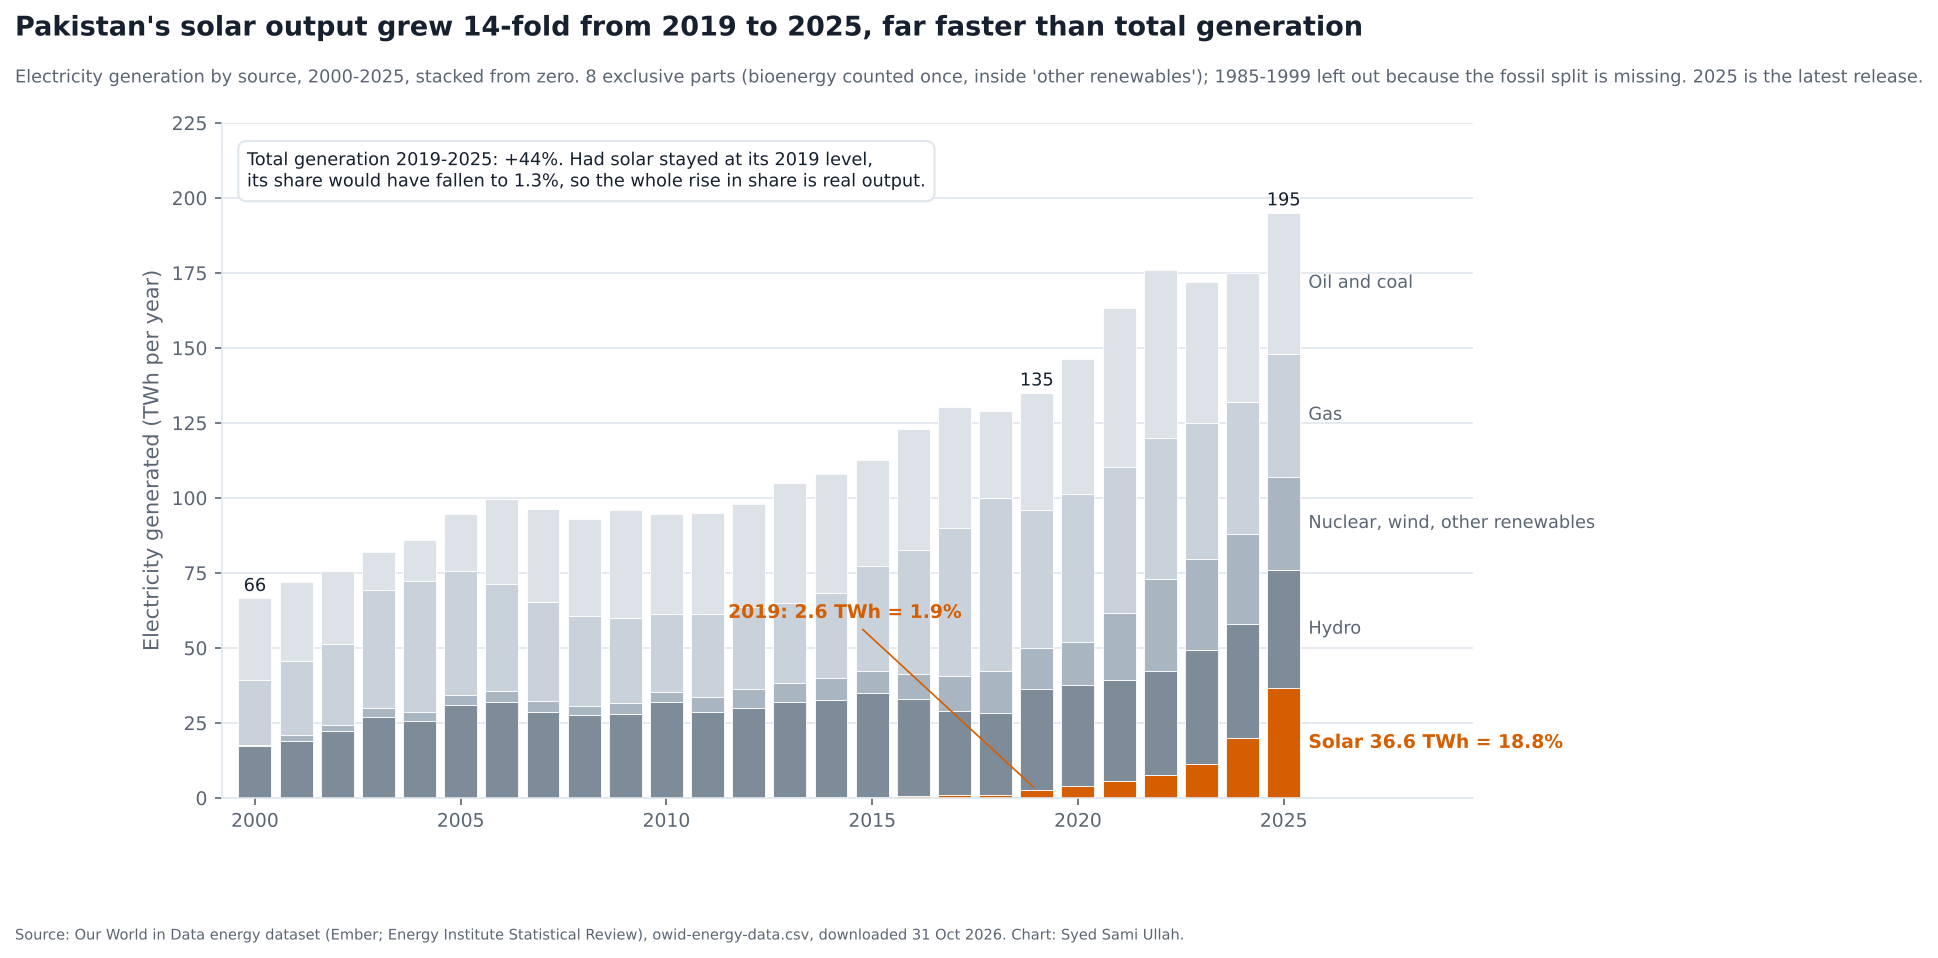

In [6]:
grp = pd.DataFrame({"Solar": clean.solar, "Hydro": clean.hydro,
                    "Nuclear, wind, other renewables": clean.nuclear + clean.wind + clean.other_renewable,
                    "Gas": clean.gas, "Oil and coal": clean.oil + clean.coal})
COL = {"Solar": ORANGE, "Hydro": "#7E8C9A", "Nuclear, wind, other renewables": "#A9B5C1", "Gas": "#C9D2DB", "Oil and coal": "#DCE2E8"}
fig, ax = plt.subplots(figsize=(12, 6))
x = grp.index.to_numpy()
bottom = np.zeros(len(grp))
for g in grp.columns:
    ax.bar(x, grp[g], bottom=bottom, color=COL[g], width=0.8, edgecolor="white", linewidth=0.4)
    if g != "Solar":
        ax.text(x[-1] + 0.6, bottom[-1] + grp[g].iloc[-1] / 2, g, va="center", fontsize=8.5, color=SOFT)
    bottom += grp[g].to_numpy()
ax.text(x[-1] + 0.6, sol[latest] / 2, f"Solar {sol[latest]:.1f} TWh = {share[latest]:.1f}%", va="center", fontsize=9, color=ORANGE, fontweight="bold")
ax.annotate(f"{b}: {sol[b]:.1f} TWh = {share[b]:.1f}%", xy=(b, sol[b]), xytext=(b - 7.5, 60), fontsize=9, color=ORANGE, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=ORANGE, lw=0.8))
for yr in (2000, b, latest):
    ax.text(yr, tot[yr] + 2.5, f"{tot[yr]:.0f}", ha="center", fontsize=8.5, color=INK)
ax.text(0.02, 0.96, f"Total generation {b}-{latest}: {(tot[latest] / tot[b] - 1) * 100:+.0f}%. Had solar stayed at its {b} level,\n"
        f"its share would have fallen to {flat:.1f}%, so the whole rise in share is real output.",
        transform=ax.transAxes, va="top", fontsize=8.5, color=INK, bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=PALETTE["grid"]))
ax.set_xlim(1999.2, latest + 4.6)
ax.set_xticks(range(2000, latest + 1, 5))
ax.set_ylim(0, 225)
ax.set_ylabel("Electricity generated (TWh per year)")
ax.grid(axis="x", visible=False)
fig.suptitle(f"Pakistan's solar output grew {sol[latest] / sol[b]:.0f}-fold from {b} to {latest}, far faster than total generation",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.905, f"Electricity generation by source, {grp.index.min()}-{latest}, stacked from zero. 8 exclusive parts (bioenergy counted once, inside "
         f"'other renewables'); 1985-1999 left out because the fossil split is missing. {latest} is the latest release.",
         fontsize=8.5, color=SOFT)
fig.subplots_adjust(top=0.86, right=0.82)
save_fig(fig, HERE / "partD_figure.png",
         note=f"Source: Our World in Data energy dataset (Ember; Energy Institute Statistical Review), owid-energy-data.csv, downloaded {DOWNLOADED}. "
              "Chart: Syed Sami Ullah.")
show()

**What this chart shows.** For most of the period solar is invisible at the bottom of the bars. From 2019 it climbs to 36.6 TWh in 2025, 18.8% of all generation, while the total grew 44%. Because the total grew too, the share rise understates the change rather than inflating it.

**The named defect.** `other_renewable_electricity` already contains `biofuel_electricity`, so a stack that draws both double-counts bioenergy, by up to 2.15 TWh a year for Pakistan (2015). The same file's `country` column also holds 87 aggregates: summing every row for 2023 gives 8.7 times the World total.